# R7 튜토리얼 — 불완전한 약물 표적 지식을 언제 믿을까?

**질문:** 학습에서 한 번도 RNA 반응을 보지 못한 약물의 978개 유전자 변화(ΔRNA)를 예측할 때, ChEMBL 표적 주석과 OmniPath 신호/전사 관계를 쓰면 화학 구조만 쓸 때보다 나아지는가?

- **한 행(unit):** (세포주, 약물 그룹). 입력은 대조군 RNA X0와 약물 구조(ECFP), 그리고 있으면 표적 주석이다.
- **정답:** 같은 plate의 처리군−대조군 RNA 차이(Δ, 실측).
- **숨긴 것:** validation·test 약물의 RNA는 어느 세포주에서도 학습에 쓰지 않았다.
- **주의:** 이 노트북은 validation 약물로만 시연한다. test 수치는 4절의 commit된 표에서만 본다.

In [1]:
%matplotlib inline
import os, sys, json
sys.path.insert(0, os.environ.get("R7_ROOT", ".")); os.chdir(os.environ.get("R7_ROOT", "."))
import numpy as np, pandas as pd, torch
import matplotlib.pyplot as plt
from src.evidence_gated_r7.data import Store, TrainStats, Knowledge
from src.evidence_gated_r7.models import R7Model
from src.evidence_gated_r7.train import SeedBank, load_graph, tensors, predict
from src.evidence_gated_r7.evaluate import unit_metrics, summarise
S = Store(); st = TrainStats(S); K = Knowledge(len(S.groups))
fr = json.load(open("manifests/evidence_gated_r7/freeze_manifest.json"))
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
T = tensors(S, st, dev)
print("units", len(S.units), "| train/val/test", len(S.train), len(S.val), len(S.test))
print("graph nodes", K.n_nodes, "edges", K.edge_index.shape[1])

units 79681 | train/val/test 56431 11731 11519
graph nodes 4696 edges 63234


## 1. 지식은 얼마나 있는가 (metadata만 사용)

`complete` = 작용 부호(억제/활성)가 있는 ChEMBL 기전이 있음, `partial` = 활성 측정만 있거나 부호가 미상, `missing` = 구조로 연결되는 human 표적 근거가 없음.
missing은 "효과 없음"이 아니라 **모름**이다. 이런 약물은 기전 보정이 정확히 0이고 화학 구조 예측만 쓴다.

In [2]:
cov = pd.read_csv("manifests/evidence_gated_r7/annotation_coverage.tsv", sep="\t").set_index("role")
cov

,complete,missing,partial,total
role,,,,
test,172,778,293,1243
train,920,3451,1431,5802
validation,160,737,346,1243


## 2. validation 약물 하나 따라가기

표적 주석이 `complete`인 validation 약물 중 측정된 세포주가 가장 많은 것을 고른다(정답 RNA를 보고 고르지 않는다).

In [3]:
u = S.units
vg = u.iloc[S.val]
vg = vg[vg.is_hcc == 0]
cand = K.status[(K.status.role == "validation") & (K.status.status == "complete")].group_idx
cnt = vg[vg.group_idx.isin(cand)].groupby("group_idx").size().sort_values(ascending=False, kind="mergesort")
g = int(cnt.index[0])
print("drug group:", S.groups.drug_group[g], "| cells measured:", cnt.iloc[0])
nodes = pd.read_csv(os.path.join(os.environ["R7_KG"], "nodes.tsv"), sep="\t").set_index("node_idx")
sd = K.by_group[g].copy(); sd["gene"] = nodes.node.reindex(sd.node).to_numpy()
sd[["gene", "mech", "actB", "actF", "sign_pos", "sign_neg", "action_unknown", "map_exact"]]

drug group: G:BRD-A35869383 | cells measured: 109


,gene,mech,actB,actF,sign_pos,sign_neg,action_unknown,map_exact
1884,ABL1,0,1,0,0,0,1,1
1885,ABL2,0,1,0,0,0,1,1
1886,BLK,0,1,0,0,0,1,1
1887,BMX,0,1,0,0,0,1,1
1888,BTK,1,1,0,0,1,0,1
1889,CSK,0,1,0,0,0,1,1
1890,EGFR,0,1,0,0,0,1,1
1891,ERBB2,0,1,0,0,0,1,1
1892,ERBB4,0,1,0,0,0,1,1
1893,FGFR2,0,1,0,0,0,1,1


In [4]:
def load(name, k=0):
    r = fr["models"][name][k]; c = r["config"]
    m = R7Model(c["arm"], load_graph(K) if c["arm"] != "chem" else None).to(dev)
    m.load_state_dict(torch.load(r["checkpoint"], map_location=dev)); m.eval()
    return m, (SeedBank(K, c.get("evidence", "on")) if c["arm"] != "chem" else None)
chem, _ = load("chem_only"); b11, bank = load("B11")
idx = np.sort(vg.index[vg.group_idx == g].to_numpy())
pc = predict(chem, T, None, idx, dev)
pb, corr, gates = predict(b11, T, bank, idx, dev, parts=True)
y = S.delta(idx)
m_c = unit_metrics(pc, y, u.cell.to_numpy()[idx]); m_b = unit_metrics(pb, y, u.cell.to_numpy()[idx])
pd.DataFrame({"cell": u.cell.to_numpy()[idx], "rmse_chem_only": m_c.rmse, "rmse_B11": m_b.rmse,
              "correction_RMS": np.sqrt((corr ** 2).mean(1)), "mean_gate": gates}).round(4)

,cell,rmse_chem_only,rmse_B11,correction_RMS,mean_gate
0,22RV1,0.4360,0.4388,0.0205,0.0658
1,A204,0.3522,0.3527,0.0214,0.0695
2,A375,0.2712,0.2757,0.0332,0.1637
3,A549,0.2767,0.2776,0.0223,0.1054
4,ASC,0.3047,0.3060,0.0323,0.1367
...,...,...,...,...,...
104,XC.P936,0.3697,0.3679,0.0353,0.2630
105,XC.R10,0.4245,0.4230,0.0239,0.1276
106,YAPC,0.2247,0.2304,0.0238,0.1565
107,YH13,0.6086,0.5721,0.1171,0.2372


**읽는 법:** `correction_RMS`는 B11의 기전 보정 크기이고, `mean_gate`는 그래프 관계가 평균적으로 얼마나 열렸는지다. gate는 모델 내부의 정보 사용량일 뿐 실제 생물학적 관계의 확률이 아니다.

## 3. 주석을 일부러 가리면? (validation, 같은 실측 RNA)

주석이 있는 validation unit에서 ChEMBL 표적 항목을 100%/50%/0% 남기고 예측해 본다. 0%는 화학 구조 예측만 쓰는 것과 같다.

In [5]:
va = S.val[S.source(S.val)]
ann = va[K.m_available[S.group_idx[va]] == 1]
ua = u.iloc[ann].reset_index(drop=True); ya = S.delta(ann)
rows = []
for keep, frac in [(100, 0.0), (50, 0.5), (0, 1.0)]:
    p = predict(b11, T, bank, ann, dev, mask_frac=frac, mask_seed=20261117)
    rows.append(dict(annotation_kept=f"{keep}%", rmse=summarise(unit_metrics(p, ya, ua.cell.to_numpy()), ua, "source")["rmse"]))
rows.append(dict(annotation_kept="chem_only model", rmse=summarise(unit_metrics(predict(chem, T, None, ann, dev), ya, ua.cell.to_numpy()), ua, "source")["rmse"]))
pd.DataFrame(rows).round(5)

,annotation_kept,rmse
0,100%,0.53793
1,50%,0.53794
2,0%,0.53916
3,chem_only model,0.53916


## 4. 전체 결과 (commit된 표, test는 동결 후 한 번)

validation 신호 판정과 test 표다. 주지표는 세포 계열을 같은 무게로 평균한 ΔRMSE이고, 낮을수록 좋다.

In [6]:
vs = json.load(open("manifests/evidence_gated_r7/val_signal_m1.json")) if os.path.exists("manifests/evidence_gated_r7/val_signal_m1.json") else json.load(open("manifests/evidence_gated_r7/val_signal.json"))
print({k: v for k, v in vs.items() if k != "mean"})
ts = pd.read_csv("manifests/evidence_gated_r7/test_summary.tsv", sep="\t")
tab = ts[ts.panel.isin(["source", "hcc_mean"])].pivot(index="model", columns="panel", values="rmse_mean").sort_values("source")
tab.round(4)

{'conditions': {'b11_minus_chem_le_m0p001': True, 'below_B01': True, 'below_B10': True, 'below_fixed': True, 'ci_b11_chem_below0': True}, 'validation_signal': True, 'b11_minus_chem': {'diff': -0.0010040693691277264, 'lo': -0.0016182855750446455, 'hi': -0.00034920985395941697}, 'shrinkage_check': {'b11_corr_rms': 0.04161563764015833, 'b11_chem_rms': 0.1759974310795466, 'ratio': 0.23645593793553196}}


panel,hcc_mean,source
model,,
v0_B10,0.6093,0.5356
B00,0.6022,0.5357
B01,0.6023,0.5358
B11_rewired,0.6020,0.5358
fixed_graph,0.6022,0.5359
B11_evidence_off,0.6023,0.5359
B11,0.6020,0.5360
xpert,0.6083,0.5360
B10,0.6023,0.5361


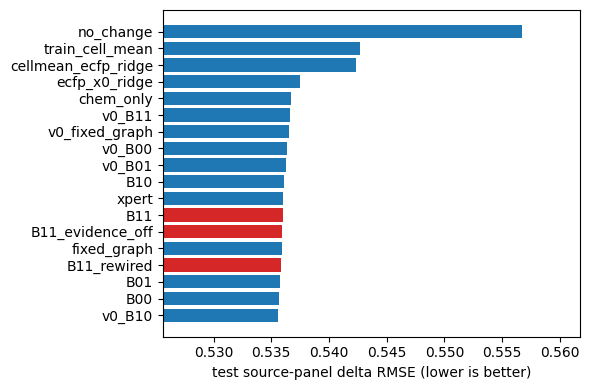

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
t = tab["source"]
ax.barh(range(len(t)), t.values, color=["C3" if n.startswith("B11") else "C0" for n in t.index])
ax.set_yticks(range(len(t))); ax.set_yticklabels(t.index); ax.set_xlim(t.min() - 0.01, t.max() + 0.005)
ax.set_xlabel("test source-panel delta RMSE (lower is better)"); fig.tight_layout(); plt.show()

In [8]:
ct = pd.read_csv("manifests/evidence_gated_r7/test_contrasts.tsv", sep="\t")
ct[ct.panel.isin(["source", "hcc_mean", "source_complete", "source_partial", "source_missing"])].round(5)

,a,b,panel,diff,lo,hi
0,B11,chem_only,source,-0.00076,-0.00147,0.00008
4,B11,chem_only,hcc_mean,-0.00020,-0.00098,0.00059
5,B11,chem_only,source_complete,-0.00100,-0.00187,0.00051
6,B11,chem_only,source_partial,-0.00104,-0.00223,-0.00028
7,B11,chem_only,source_missing,0.00000,0.00000,0.00000
...,...,...,...,...,...,...
208,v0_B11,B11,source,0.00063,-0.00063,0.00145
212,v0_B11,B11,hcc_mean,0.00436,0.00214,0.00637
213,v0_B11,B11,source_complete,0.00016,-0.00217,0.00119
214,v0_B11,B11,source_partial,0.00153,0.00030,0.00292


In [9]:
stress = pd.read_csv("manifests/evidence_gated_r7/annotation_stress.tsv", sep="\t")
stress[stress.panel == "source"].round(5)

,model,annotation,panel,rmse,n_units,lo,hi
0,B11,kept_100,source,0.53882,6304,NaN,NaN
4,B11,kept_50,source,0.53883,6304,NaN,NaN
8,B11,kept_50_minus_kept_100,source,0.00001,6304,-0.00001,0.00003
9,B11,kept_0,source,0.53979,6304,NaN,NaN
13,B11,kept_0_minus_kept_100,source,0.00097,6304,0.00004,0.00181
14,B10,kept_100,source,0.53892,6304,NaN,NaN
18,B10,kept_50,source,0.53893,6304,NaN,NaN
22,B10,kept_50_minus_kept_100,source,0.00002,6304,-0.00000,0.00004
23,B10,kept_0,source,0.53979,6304,NaN,NaN
27,B10,kept_0_minus_kept_100,source,0.00088,6304,0.00010,0.00155


## 5. 정리

- 결론은 `reports/evidence_gated_r7/RESULTS.md`와 `CLAIMS_AND_LIMITATIONS.md`에 있다. 여기 숫자는 그 표를 다시 보여 줄 뿐이다.
- 평균 오차가 조금 바뀌어도 그것이 기전을 발견했다는 뜻은 아니다. gate·attention을 인과 관계로 읽지 않는다.
- 범위: CMap 2020 Level 3, 10 µM·24 h, 978 landmark, ChEMBL 37 + OmniPath(2026-11-18 다운로드), 이미 공개·노출된 benchmark의 후속 평가.